# Creating a ground truth by using label transfer from one annotated slide to the other slides. 

In [13]:
from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.neighbors import KNeighborsClassifier
import gc

%load_ext autoreload
%autoreload 2

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
basedir = Path("../data")
dir_uni =  "01_preprocessing/unimodel/metadata"
samples = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5", "CRC_P6_5mm", "CRC_P11mm"]

def label_transfer_dir(sample_id):
    """data/{sample}/02_baselines/label_transfer -- matches functions/label_transfer.py's OUT_DIR_TEMPLATE."""
    return basedir / sample_id / "02_baselines/label_transfer"

### Patch-level label transfer

Runs `functions/label_transfer.py` -- two classifiers (UNI image embeddings, and
aggregated-transcriptomics-per-patch) trained on the CRC_P2 ground truth and
applied to every other sample. Both the reference and every target are sourced
from `filtered_WSI_patch_embeddings.h5ad`, so background/no-tissue patches
(identified via the leiden-cluster filtering in `02_downstream_analysis_uni.ipynb`)
are excluded from training and prediction.

In [ ]:
import importlib
from functions import label_transfer as lt

importlib.reload(lt)  # pick up any edits without restarting the kernel

# min_compound_label_count: None -> collapse every tissuetype to its dominant
#   component (6 base classes). An int (e.g. 100) instead keeps common
#   border-region labels (e.g. "Veins_Neoplasm") as their own class.
# neoplasm_prior_weight_on_normal: None disables the prior entirely. 0.0 hard-masks
#   Neoplasm on "Normal_*" slides; e.g. 0.1 soft-downweights it instead.
# model_type: "mlp" (default, small GPU neural net) or "knn" (sklearn k-NN,
#   CPU, no training loop -- simpler, handles rare classes naturally).
lt.main(
    min_compound_label_count=50,
    neoplasm_prior_weight_on_normal=0.1,
    model_type="mlp",
)

In [ ]:
# Merge every target sample's predictions into one combined AnnData:
# data/combined/02_baselines/label_transfer/combined_patch_predictions.h5ad
# Uses discover_target_samples() so this always matches exactly what lt.main()
# just produced (CRC_P2 is the reference, not a prediction target, so it's
# excluded here too, same as in main()).
from functions.merge import merge_anndatas

merged_predictions = merge_anndatas(
    lt.discover_target_samples(),
    "{basedir}/{sample}/02_baselines/label_transfer/{filename}",
    "{sample}_patch_predictions.h5ad",
    basedir,
    obs_name_mode="unique",
    per_sample_pca_key=None,
)

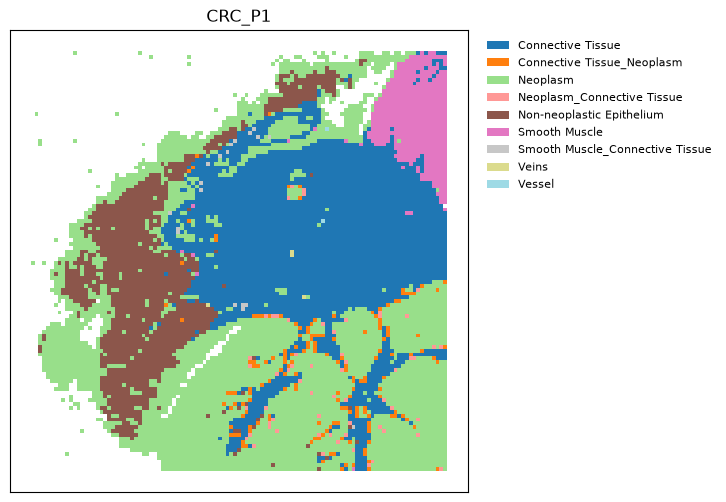

In [10]:
# plot one sample based on patch-level label transfer

sample_id = samples[0]  # swap for any sample_id you want to inspect or set string like "CRC_P1"
result_dir = label_transfer_dir(sample_id)
if sample_id == "CRC_P2":
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_with_annotation.h5ad")
else:
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_patch_predictions.h5ad")


# TODO: optionally fix spatial key, so spatial information can also be somewhere else
pl.plot_spatial_labels(
    adata_sample,
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # or "predicted_tissuetype_transcriptomics"
    title=sample_id,
    mode="patch",
)
plt.show()

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


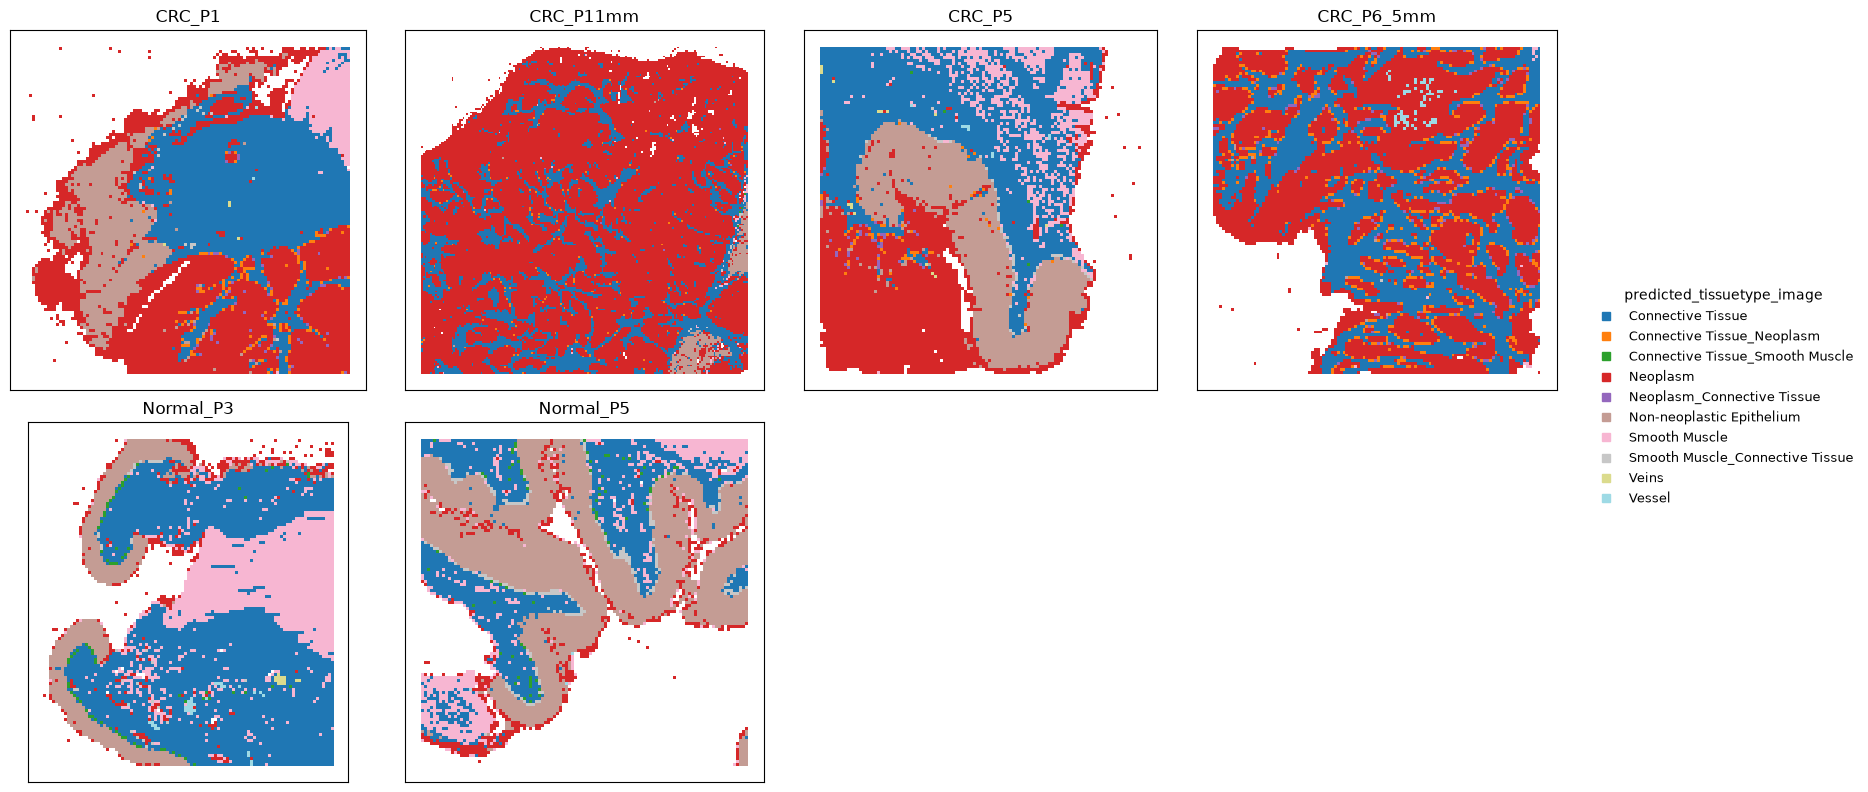

In [11]:
#  plot all samples based on patch-level label transfer
obs_list, spatial_list = [], []

for sample_id in samples:
    out_file = label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad"
    if not out_file.exists():
        continue

    a = sc.read_h5ad(out_file, backed="r")
    obs = a.obs.copy()
    obs["Slide_ID"] = sample_id
    obs_list.append(obs)
    spatial_list.append(np.asarray(a.obsm["spatial"]))
    del a

obs_all = pd.concat(obs_list, axis=0, ignore_index=True)
spatial_all = np.vstack(spatial_list)

# dummy 1-column X: we only need obs + obsm for plotting
adata_all = ad.AnnData(X=np.zeros((obs_all.shape[0], 1)), obs=obs_all)
adata_all.obsm["spatial"] = spatial_all
adata_all.obs["Slide_ID"] = adata_all.obs["Slide_ID"].astype("category")

pl.plot_spatial_labels_grid(
    adata_all,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # swap to "predicted_tissuetype_transcriptomics" to compare
    ncols=4,
    mode="patch",
)
plt.show()

#### Label transfer, with Harmony batch correction (comparison run)
Same reference/target label transfer as above, but the image classifier is trained and applied on a joint PCA + Harmony-corrected embedding (keyed on `Slide_ID`) instead of the raw UNI embedding, to check whether removing slide-to-slide batch effects improves the image-based predictions. This is an *additional* run for comparison: outputs go to `{sample}_patch_predictions_harmony.h5ad` / `combined_patch_predictions_harmony.h5ad`, alongside (not replacing) the originals. Code + resulting AnnData objects to be cleaned up later once we decide which approach to keep.

In [ ]:
import importlib
from functions import label_transfer as lt

importlib.reload(lt)  # pick up any edits without restarting the kernel

# Same knobs as the raw run above, but use_harmony=True: trains/predicts the image
# classifier on a joint PCA + Harmony-corrected embedding (keyed on Slide_ID) instead
# of raw UNI .X. Writes to "{sample}_patch_predictions_harmony.h5ad" (raw outputs
# untouched), so both can be compared side by side.
lt.main(
    min_compound_label_count=50,
    neoplasm_prior_weight_on_normal=0.1,
    model_type="mlp",
    use_harmony=True,
)

In [ ]:
# Merge the harmony-corrected predictions into one combined AnnData:
# data/combined/02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad
from functions.merge import merge_anndatas

merged_predictions_harmony = merge_anndatas(
    lt.discover_target_samples(),
    "{basedir}/{sample}/02_baselines/label_transfer/{filename}",
    "{sample}_patch_predictions_harmony.h5ad",
    basedir,
    obs_name_mode="unique",
    per_sample_pca_key=None,
)

Merged 6/6 sample(s) -> ../data/combined/02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


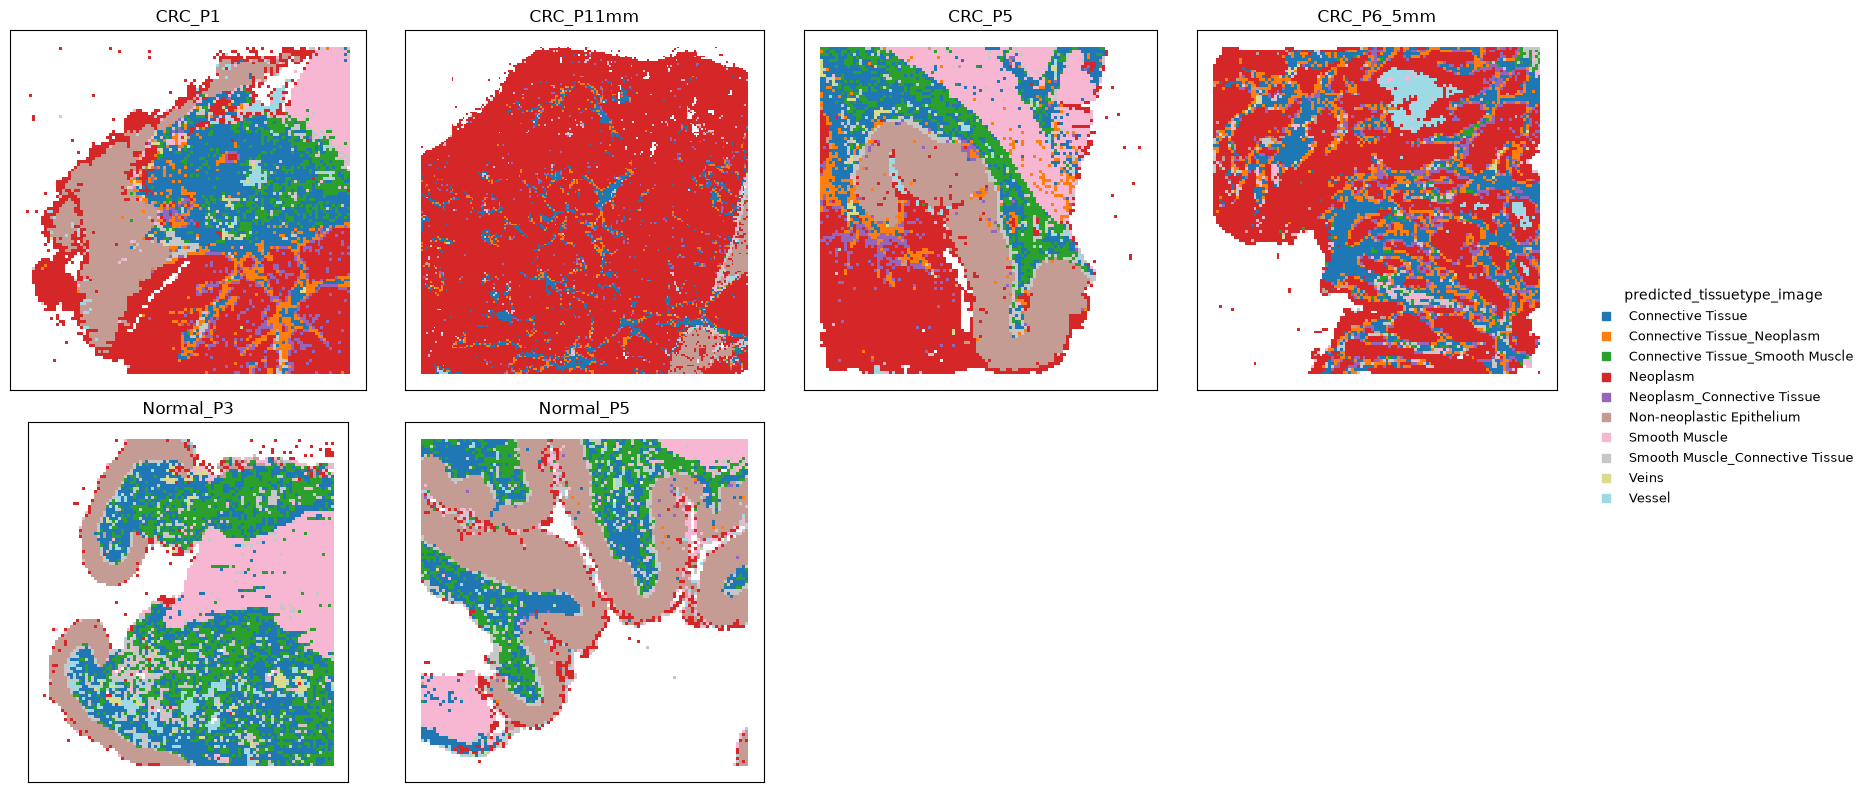

In [ ]:
#  plot all samples based on patch-level label transfer
obs_list, spatial_list = [], []

for sample_id in samples:
    out_file = label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions_harmony.h5ad"
    if not out_file.exists():
        continue

    a = sc.read_h5ad(out_file, backed="r")
    obs = a.obs.copy()
    obs["Slide_ID"] = sample_id
    obs_list.append(obs)
    spatial_list.append(np.asarray(a.obsm["spatial"]))
    del a

obs_all = pd.concat(obs_list, axis=0, ignore_index=True)
spatial_all = np.vstack(spatial_list)

# dummy 1-column X: we only need obs + obsm for plotting
adata_all = ad.AnnData(X=np.zeros((obs_all.shape[0], 1)), obs=obs_all)
adata_all.obsm["spatial"] = spatial_all
adata_all.obs["Slide_ID"] = adata_all.obs["Slide_ID"].astype("category")

pl.plot_spatial_labels_grid(
    adata_all,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  
    ncols=4,
    mode="patch",
)
plt.show()

# Histology
This section covers a few single-omics evaluation. 
1. **Evaluation of the preprocessing steps**: This section focusses on illustrating the preprocessing steps done on histology. This gives as an overview over parameters such as patch count and predicted disease status but also label distribution and more.    
2. We will also evaluate the **clustering performed on the PCA results** of the patch embeddings, independent of the ground truth. Here, we do not have labels for the clusters.

#### Evaluation of preprocessing steps
This first cell gives us an overview over some basic information such as patch count and disease status prediction of the label transfer.

In [7]:
meta = ad.read_h5ad(basedir / "combined" / dir_uni / "WSI_patch_metadata.h5ad", backed="r").obs
filt = ad.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
pred = sc.read_h5ad(basedir / "combined" / "02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad", backed="r").obs

corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
corners.columns = ["x_min", "x_max", "y_min", "y_max"]

summary = corners.reindex(samples)
summary.index.name = "Slide_ID"
summary["n_patches_total"] = meta["Slide_ID"].value_counts()
summary["n_patches_filtered"] = filt["Slide_ID"].value_counts()
summary["status_original"] = summary.index.map(lt.get_disease_status)
summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()

summary

/tmp/ipykernel_63482/3468547788.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
/tmp/ipykernel_63482/3468547788.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()


,x_min,x_max,y_min,y_max,n_patches_total,n_patches_filtered,status_original,predicted_diseased_tissue_pct
Slide_ID,,,,,,,,
CRC_P1,0,24192,12137,36553,11990,9197,CRC,44.612374
CRC_P2,40580,64996,0,22400,11110,9592,CRC,NaN
CRC_P5,44268,68460,39511,63703,11881,9467,CRC,33.875568
Normal_P3,0,21504,9496,33688,10573,8292,Normal,2.629040
Normal_P5,41684,65876,26477,50669,11881,8063,Normal,6.176361
CRC_P6_5mm,4582,29894,4813,30125,12996,10983,CRC,70.399709
CRC_P11mm,12254,52574,59,40379,32761,29959,CRC,89.569078


Now, we take a closer look at the label distribution per slide. 
Note, that this is based purely on the annotation labels provided in the ground truth. Possible further labels are only evaluated later, when incorporating the results from the autoencoder. 

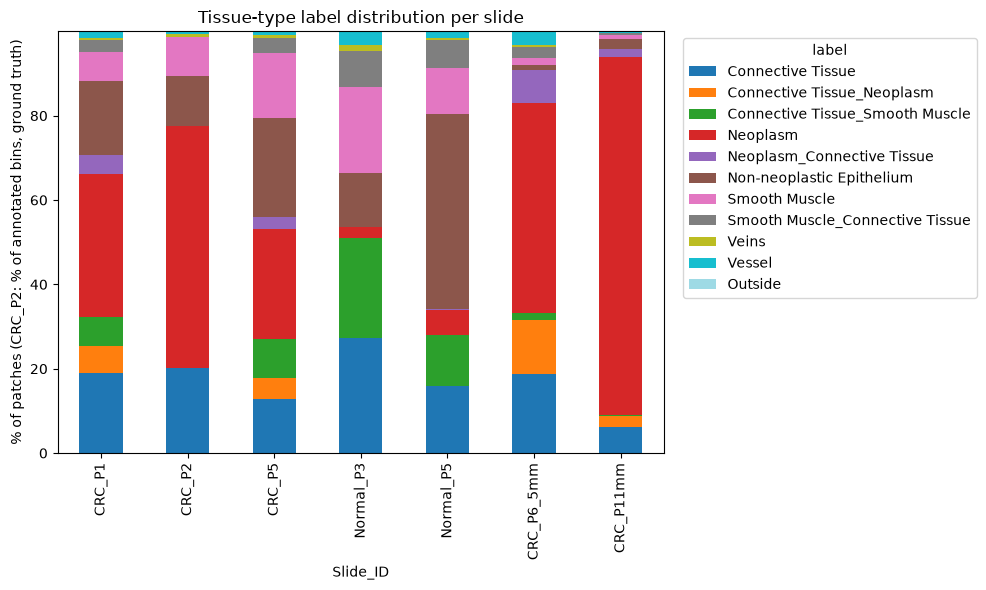

In [8]:
crc_p2_annotation = sc.read_h5ad(label_transfer_dir("CRC_P2") / "CRC_P2_with_annotation.h5ad", backed="r").obs["annotation"]
crc_p2_dist = crc_p2_annotation.value_counts(normalize=True) * 100
crc_p2_dist.name = "CRC_P2"

label_dist = pd.crosstab(pred["Slide_ID"], pred["predicted_tissuetype_image"], normalize="index") * 100
label_dist = pd.concat([label_dist, crc_p2_dist.to_frame().T]).reindex(samples)

ax = label_dist.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="tab20")
ax.set_ylabel("% of patches (CRC_P2: % of annotated bins, ground truth)")
ax.set_xlabel("Slide_ID")
ax.set_title("Tissue-type label distribution per slide")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="label")
plt.tight_layout()
plt.show()

#### 2nd ground truth: Leiden clustering on UNI PCA

We will perform three types of leiden clustering:
1. In the first step, we will perform leiden clustering on PCA values of UNI2-h patch embeddings separately for each slide.
2. During the second step, we perfom leiden clustering over all slides combined. 

**Step 1: Leiden per Sample**
As a first step, we perform leiden *per sample*, so not over all samples at once. 

In [10]:
sample = "CRC_P2"
adata_single = sc.read_h5ad(basedir / sample / dir_uni / "filtered_WSI_patch_embeddings.h5ad")
adata_combined = sc.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad")

We now plot the leiden clustering result next to the result of the label transferred ground truth for the same slide next to each other.
By changing the parameter `sample` in the cell above, you can change the slide you see below.

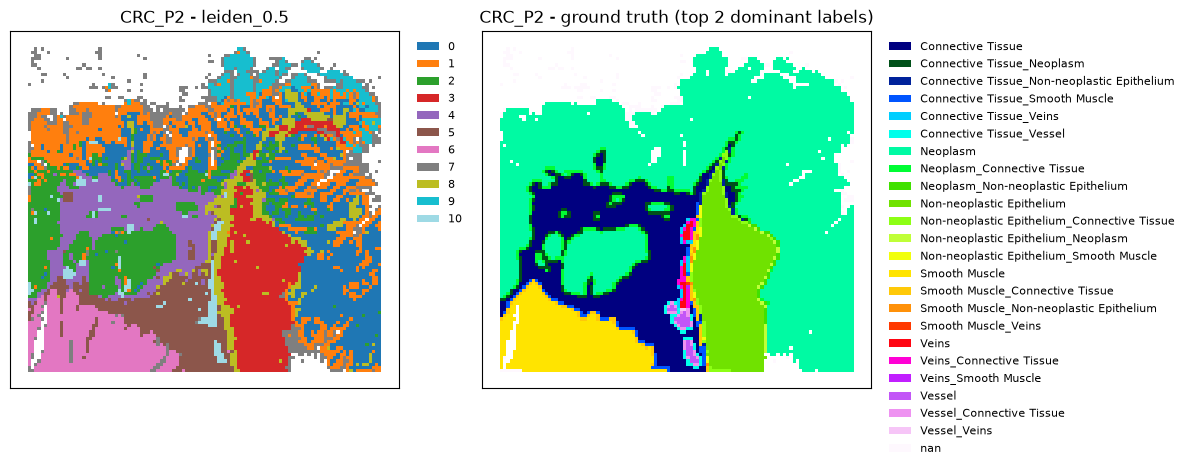

In [ ]:
adata_single.obs["tissuetype_top2"] = adata_single.obs["tissuetype"].astype(str).str.split("_").str[:2].str.join("_")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pl.plot_spatial_labels(
    adata_single,
    spatial_key="spatial",
    label_key="leiden_0.5",
    title=f"{sample} - leiden_0.5",
    mode="patch",
    ax=axes[0],
)
pl.plot_spatial_labels(
    adata_single,
    spatial_key="spatial",
    label_key="tissuetype_top2",
    title=f"{sample} - ground truth (top 2 dominant labels)",
    mode="patch",
    ax=axes[1],
)
plt.tight_layout()
plt.show()

To compare the results, we test the ARI on all slides.
We perform two comparisons: 
- `ARI_full` — the full compound label as basis: tissuetype (real ground truth) for CRC_P2, predicted_tissuetype_image (label-transfer prediction) for the other six slides.
- `ARI_top2` — same basis labels, but collapsed to only the two most dominant _-joined components first (reusing the same top-2 truncation logic from the previous cell), so triple/quadruple compound labels merge into their top-2 equivalent before scoring.

In [9]:
from sklearn.metrics import adjusted_rand_score

def get_basis_and_leiden(sample_id):
    """Ground truth (CRC_P2) or label-transfer prediction (other slides) vs. leiden_0.5, same patch order."""
    if sample_id == "CRC_P2":
        obs = sc.read_h5ad(basedir / sample_id / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
        basis = obs["tissuetype"]
    else:
        obs = sc.read_h5ad(label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad", backed="r").obs
        basis = obs["predicted_tissuetype_image"]
    return basis.astype(str), obs["leiden_0.5"]

def top2(labels):
    return labels.str.split("_").str[:2].str.join("_")

ari_rows = []
for sample_id in samples:
    basis, leiden = get_basis_and_leiden(sample_id)
    ari_rows.append({
        "Slide_ID": sample_id,
        "ARI_full": adjusted_rand_score(basis, leiden),
        "ARI_top2": adjusted_rand_score(top2(basis), leiden),
    })

ari_df = pd.DataFrame(ari_rows).set_index("Slide_ID")
ari_df

,ARI_full,ARI_top2
Slide_ID,,
CRC_P1,0.345434,0.345434
CRC_P2,0.295072,0.295096
CRC_P5,0.481944,0.481944
Normal_P3,0.325951,0.325951
Normal_P5,0.326701,0.326701
CRC_P6_5mm,0.311723,0.311723
CRC_P11mm,0.202355,0.202355


For comparative overview, we now plot all images for PCA=50 and leiden resolution=0.2.

**2nd step: Leiden WITHOUT batch correction over all samples**

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


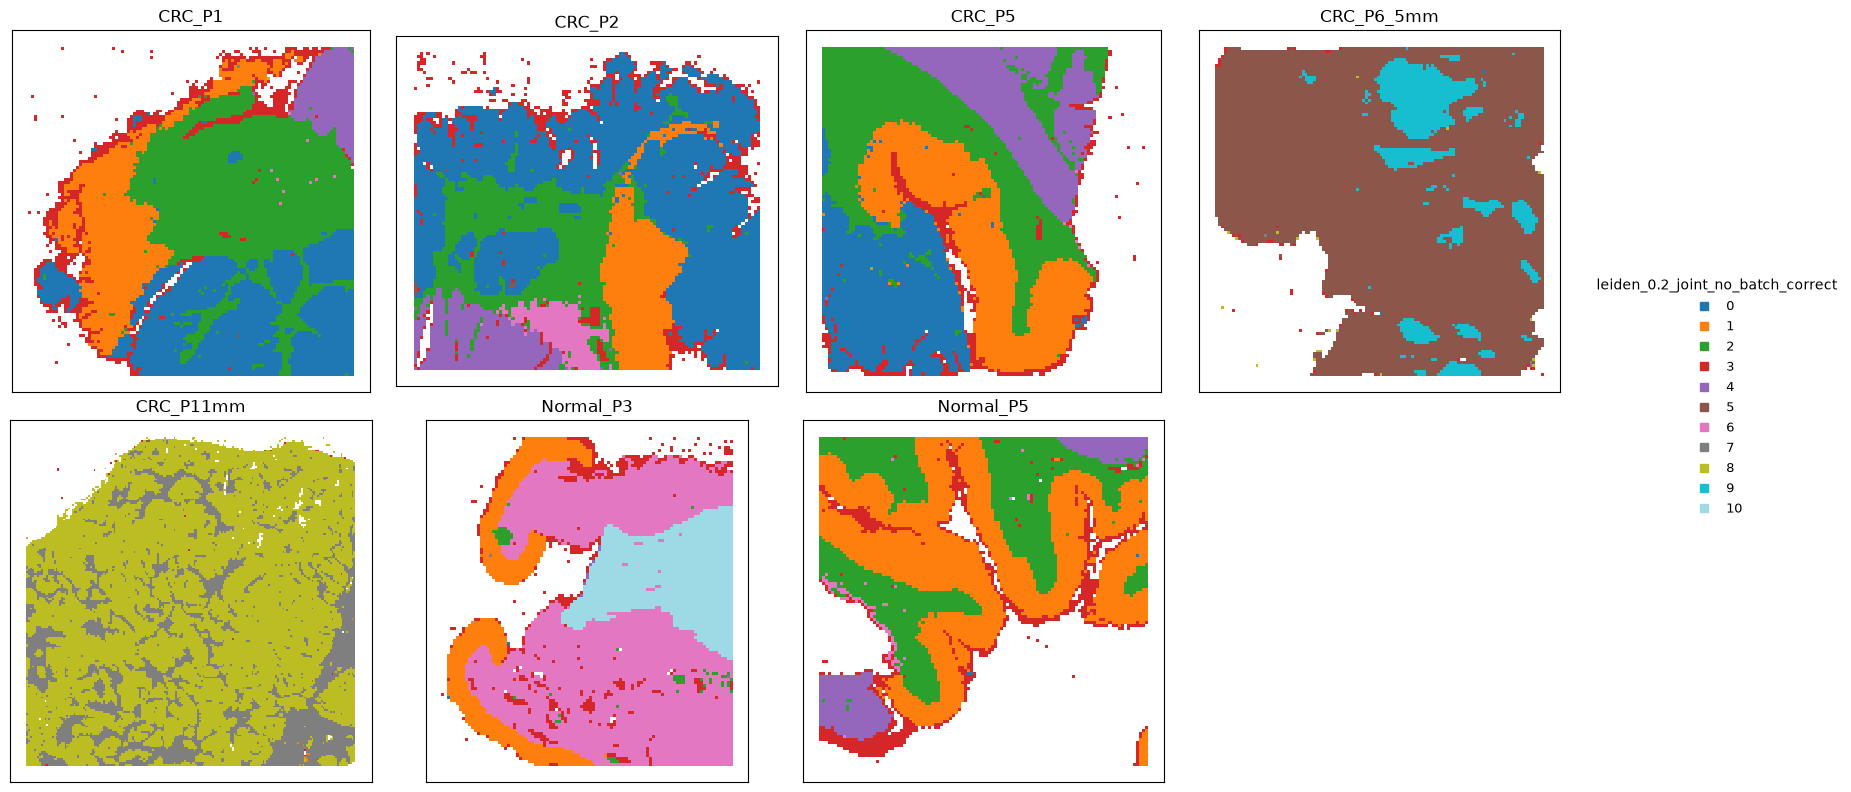

In [12]:
# run PCA, neighbor graph and leiden on all samples at once
sc.pp.pca(adata_combined, n_comps=50)
sc.pp.neighbors(adata_combined)          
sc.tl.leiden(
    adata_combined,
    resolution=0.2,
    key_added="leiden_0.2_joint_no_batch_correct",
    flavor="igraph",
    n_iterations=2,
    directed=False,
)

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="leiden_0.2_joint_no_batch_correct", 
    ncols=4,
    mode="patch",
)
plt.show()

**3rd: Leiden WITH batch correction** 

In [ ]:
# Issue:
# here, Slide_ID (the thing you'd batch-correct on) is in exact 1:1 correspondence with the label you're trying to predict. 
# Every slide has exactly one disease status — no two slides share a condition the way replicate samples usually do in scRNA-seq batch correction. 
# So "correct for Slide_ID" and "remove the disease signal" are mathematically the same operation here. Harmony (or any batch-correction method keyed on Slide_ID) 
# can't distinguish "this is slide-to-slide technical variation" from "this is the biological CRC-vs-Normal difference," 
# because nothing in the data lets it tell those apart — they're perfectly confounded.

2026-08-18 15:29:39,108 - harmonypy - INFO - Running Harmony
2026-08-18 15:29:39,109 - harmonypy - INFO -   Parameters:
2026-08-18 15:29:39,110 - harmonypy - INFO -     max_iter_harmony: 10
2026-08-18 15:29:39,110 - harmonypy - INFO -     max_iter_kmeans: 4
2026-08-18 15:29:39,111 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-08-18 15:29:39,111 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-08-18 15:29:39,112 - harmonypy - INFO -     nclust: 100
2026-08-18 15:29:39,112 - harmonypy - INFO -     block_size: 0.05
2026-08-18 15:29:39,112 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-08-18 15:29:39,113 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2.]
2026-08-18 15:29:39,113 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-08-18 15:29:39,114 - harmonypy - INFO -     verbose: True
2026-08-18 15:29:39,114 - harmonypy - INFO -     random_state: 0
2026-08-18 15:29:39,114 - harmonypy - INFO -   Data: 50 PCs × 85553 cells
2026-08-18 15:29:39,114 - harmonypy

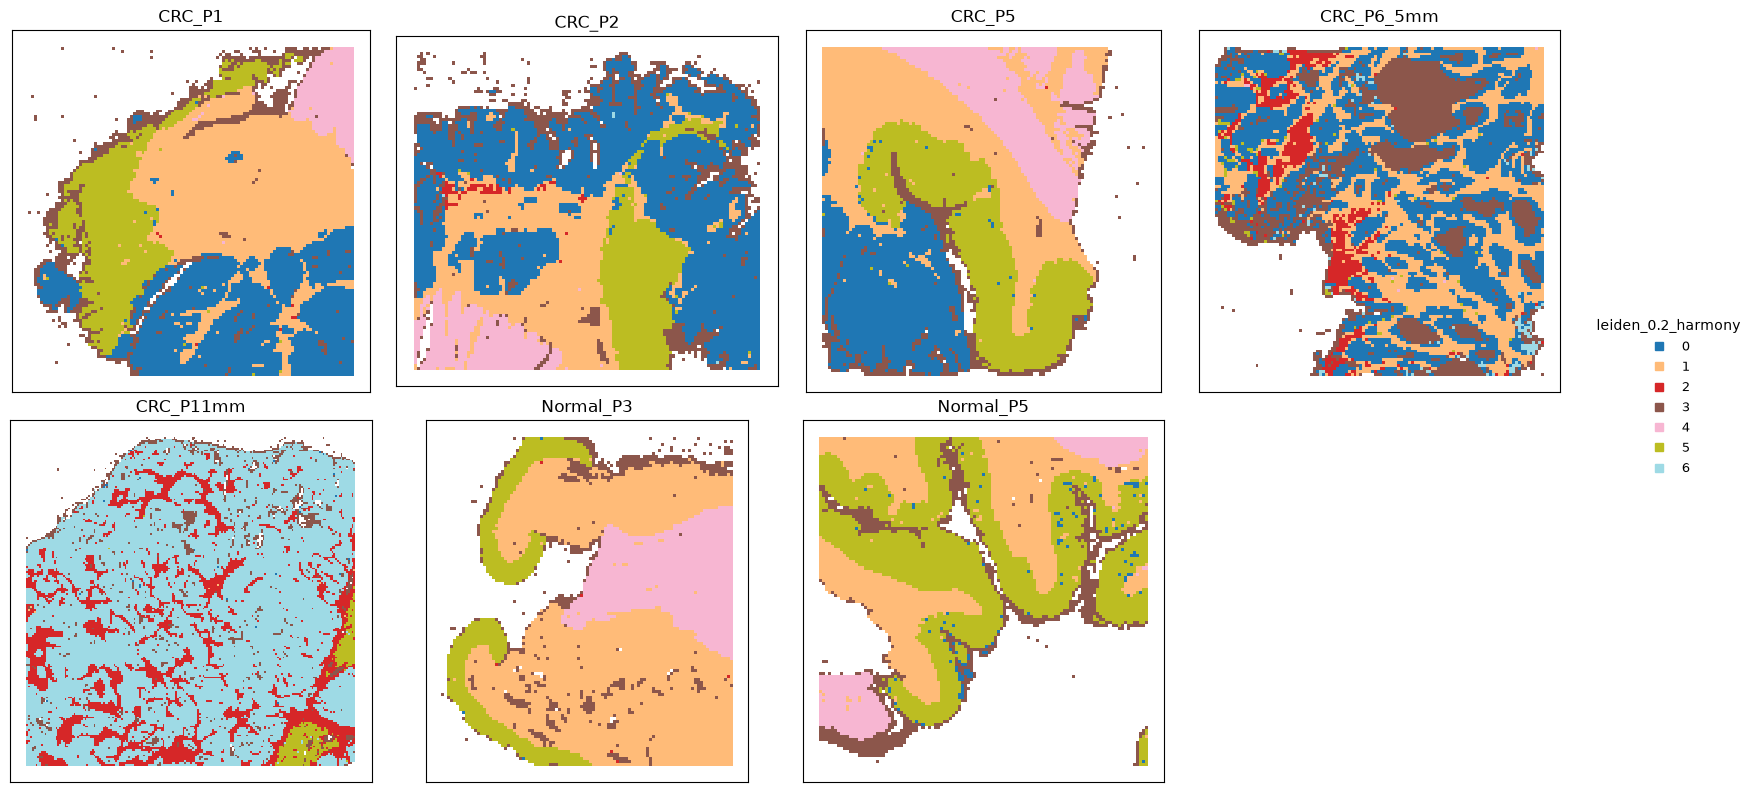

In [13]:
import harmonypy

# Harmony-correct the joint PCA, keyed on Slide_ID, then re-cluster on the corrected representation.
# NOTE: bypassing sce.pp.harmony_integrate -- it does `Z_corr.T`, which was correct for
# harmonypy<2.0 (Z_corr was (n_pcs, n_obs)) but double-transposes with harmonypy>=2.0,
# where Z_corr is already (n_obs, n_pcs).
harmony_out = harmonypy.run_harmony(adata_combined.obsm["X_pca"].astype(np.float64), adata_combined.obs, "Slide_ID")
adata_combined.obsm["X_pca_harmony"] = harmony_out.Z_corr

sc.pp.neighbors(adata_combined, use_rep="X_pca_harmony")
sc.tl.leiden(
    adata_combined,
    resolution=0.2,
    key_added="leiden_0.2_harmony",
    flavor="igraph",
    n_iterations=2,
    directed=False,
)

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="leiden_0.2_harmony",
    ncols=4,
    mode="patch",
)
plt.show()

# Transcriptomics

### 1st ground truth: assign labels to cells based on bin labeling
<span style="color:red">Check in eval: influence of lower UMI!!!.</span>

#### Evaluation of preprocessing results

TO DO 
- print UMI distribution per slide and then also over all slides
- print gene expression distribution per cell per slide
- then print SVGs in comparison to that
- print stats on cell count before and after filtering
- also print SVG count per slide, SVGs all have in common and SVGs that vary, and more
- Same for HVGs (note: see cell 45 ff in custom_binning.ipynb for the last thing)

In [ ]:
# IDEA
# 1. Load filtered custom bins
# 2. Load unfiltered bins with annotation 
#    --> merge annotation to filtered custom bins (index should still be barcodes)
# 3. somehow aggregate annotation if they are not the same
# 4. transfer cell labels using cell id to count_area_filtered_adata
# 5. Compare ARI to ARI from just bins? wie ? 
# 6. Plot one or all samples

### 2nd ground truth: Clustering based on just HVGs

In [ ]:
# 1. Separate HVG was already performed: just cluster and plot
# 2. Try other leiden resolutions, plot cluster number per patch

In [ ]:
# 1. Combined HVG: calculate combined HVGs over all samples
# 2. Cluster again and plot leiden resolution cluster results
# 3. Also check: can we see diseased status per patient? 
# 4. Potentially: plot dieseased and healthy tissue as binary mask

### 3rd Ground truth: Clustering based on just SVGs

In [6]:
# same as above

### 4th ground truth: Clustering based on just PCA

In [ ]:
# same as above

### 5th Ground truth: Any SpaceRanger outputs?

In [ ]:
# same as above

## Baselines

### Potentially Autoencoder without smaller patches just the big ones? 

# Evaluation from alignment results

### Token-augmented autoencoder: cell (trans) + cell (token/histology) embedding UMAP

Loads only `Slide_ID` plus the `X_dae_trans_cell` (64-dim, transcriptomics) and
`X_dae_token_cell` (64-dim, cell-level histology-from-tokens) `obsm` arrays
directly via `h5py` -- skips `.X` and every other `obsm` array (`X_dae_hist_patch`,
`X_dae_trans_patch`, `X_dae_joint_patch`, `X_dae_trans_token_hist_concat`,
`X_pca_per_sample_raw`, `spatial`) entirely. The full file is 1,193,045 cells;
loading everything the way plain `sc.read_h5ad`/`ad.read_h5ad(..., backed="r")`
would (all 8 `obsm` arrays eagerly, ~2.7GB, plus `.X` if not backed) is the
"file might be too large for RAM" case -- this avoids it by reading exactly the
two arrays needed.

Deliberately excludes `X_dae_hist_patch`/`X_dae_trans_patch`/`X_dae_joint_patch`
from this plot: this run had `CONFIG["max_contrast_weight"]=0.0`, so the
patch-level trans<->hist alignment never actually trained (`contrast_w=0.00` for
all 100 epochs in the log) -- only the cell-level trans+token embeddings reflect
real trained alignment right now.

Subsamples up to `MAX_CELLS_PER_SLIDE` cells **per slide** (stratified, not
proportional) before computing neighbors/UMAP: per `diagnose_pipeline.py`'s
output, CRC_P11mm alone is 59% of all cells, so an unstratified random sample
would be dominated by it and the other 6 slides would barely register.

Loaded 56000 cells (of 1193045 total) across 7 slides
CRC_P1        8000
CRC_P2        8000
CRC_P5        8000
CRC_P6_5mm    8000
CRC_P11mm     8000
Normal_P3     8000
Normal_P5     8000
Name: count, dtype: int64


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


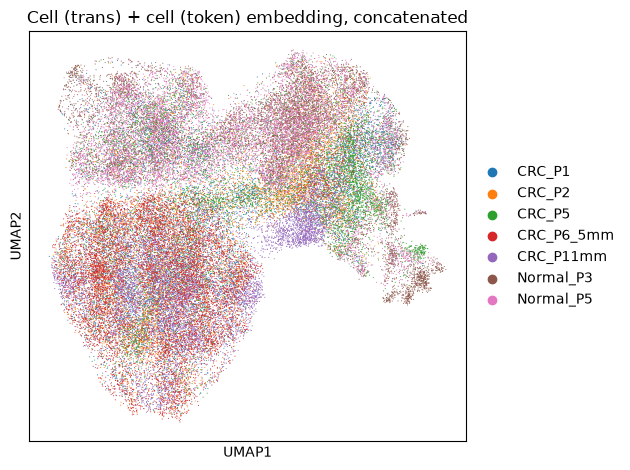

In [15]:
import h5py

TOKEN_RUN_PATH = basedir / "combined/03_integration/autoencoders/002um/with_tokens/trans_with_dae_latents.h5ad"
MAX_CELLS_PER_SLIDE = 8000
RANDOM_SEED = 0

# Selective h5py load -- see markdown above for why (RAM). sample_idx must stay
# sorted: h5py's fancy indexing on a Dataset requires increasing order.
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    slide_cats = f["obs/Slide_ID/categories"].asstr()[:]
    slide_codes = f["obs/Slide_ID/codes"][:]

    rng = np.random.default_rng(RANDOM_SEED)
    sample_idx = []
    for code in range(len(slide_cats)):
        idx = np.nonzero(slide_codes == code)[0]
        if len(idx) > MAX_CELLS_PER_SLIDE:
            idx = rng.choice(idx, size=MAX_CELLS_PER_SLIDE, replace=False)
        sample_idx.append(idx)
    sample_idx = np.sort(np.concatenate(sample_idx))

    trans_cell = f["obsm/X_dae_trans_cell"][sample_idx]
    token_cell = f["obsm/X_dae_token_cell"][sample_idx]

slide_id = pd.Categorical.from_codes(slide_codes[sample_idx], categories=slide_cats)
print(f"Loaded {len(sample_idx)} cells (of {len(slide_codes)} total) across {len(slide_cats)} slides")
print(pd.Series(slide_id).value_counts())

# concatenate trans (cell-level transcriptomics) + token (cell-level histology) --
# NOT the precomputed X_dae_trans_token_hist_concat, which also folds in
# X_dae_hist_patch (the untrained patch-level branch, see markdown above)
concat_emb = np.concatenate([trans_cell, token_cell], axis=1).astype(np.float32)

emb_adata = ad.AnnData(X=concat_emb, obs=pd.DataFrame({"Slide_ID": slide_id}))
sc.pp.neighbors(emb_adata, use_rep="X")
sc.tl.umap(emb_adata)

sc.pl.umap(emb_adata, color="Slide_ID", title="Cell (trans) + cell (token) embedding, concatenated", show=False)
plt.tight_layout()
plt.show()

### Leiden clusters + dominant (marker) genes on the same UMAP

`Slide_ID` came out completely mixed above (no batch-driven separation) -- next
question is whether there's real structure at all, and whether it tracks actual
gene expression. Clusters the trans+token embedding (`emb_adata`, same neighbors
graph and `sample_idx` subsample as above), then finds each cluster's top marker
gene restricted to the **SVG panel** -- the same 385 genes `trans_enc` actually
sees as input (`get_svg_union_mask`/`X_svg` in `train_autoenc_token.py`, the
union of `varm["spatially_variable_per_sample"]` across all 7 samples -- matches
the "385 SVGs selected (union)" training log line), not the full 18,085-gene
panel, since that's the mechanistically relevant gene set and keeps this fast.
(Note: `var["spatially_variable"]` is a stale, unrelated column with only 143
genes -- don't use it; see the code cell's comment for why.)

RAM: reads only the same `sample_idx` rows AND only the SVG columns straight off
disk via `anndata.io.sparse_dataset` wrapping `f["X"]` directly -- the
(1,193,045 x 18,085) sparse count matrix itself is never materialized, only the
small (56000 x 385) slice needed here (row-subset ~2s, column-subset instant).

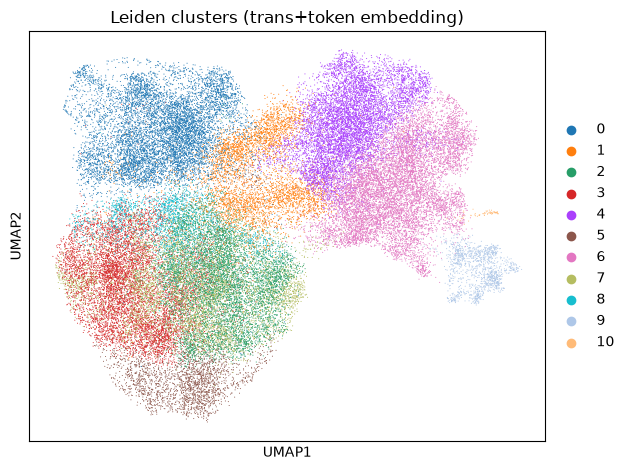

SVG union: 385 genes
Top marker gene per cluster (SVG panel): ['PIGR', 'MT-ATP6', 'MT-ND4L', 'IGKC', 'CEACAM5', 'COL3A1', 'OLFM4', 'TAGLN', 'VIP']


/tmp/ipykernel_15916/3811552112.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


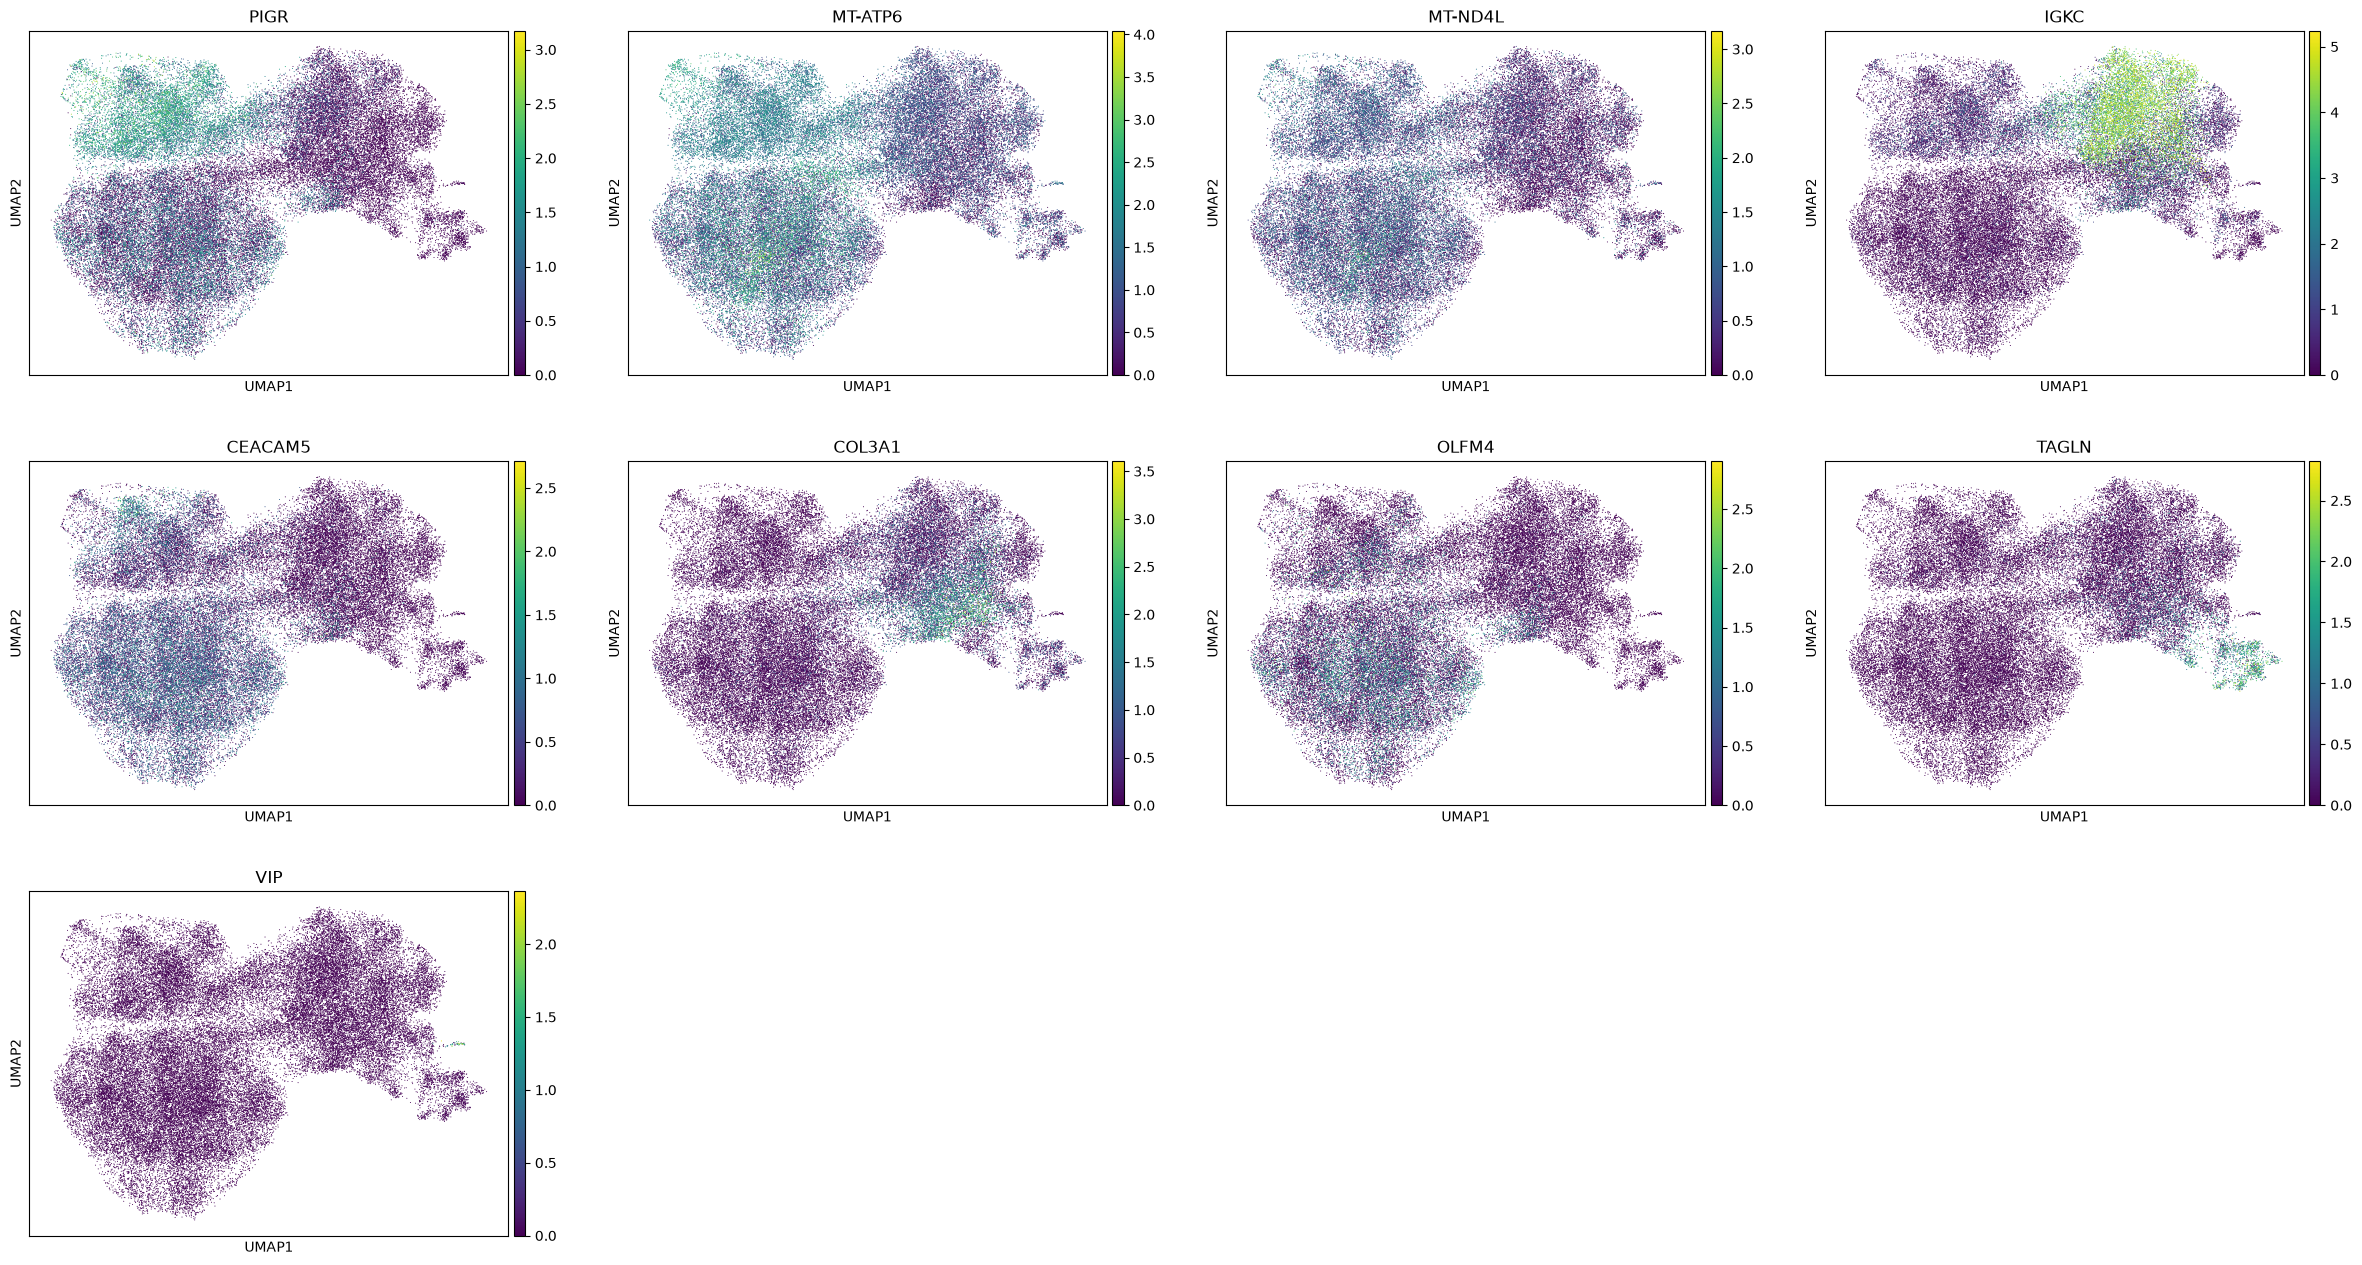

In [29]:
from anndata.io import sparse_dataset

# 1. Leiden clustering on the neighbors graph already computed on the trans+token
# embedding (previous cell) -- needed both for the marker-gene panel below and
# for the spatial-by-cluster plot after it.
sc.tl.leiden(emb_adata, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
sc.pl.umap(emb_adata, color="leiden", title="Leiden clusters (trans+token embedding)", show=False)
plt.tight_layout()
plt.show()

# 2. Marker genes per cluster, SVG panel only (see markdown above). sparse_dataset
# wraps the on-disk CSR group directly -- row-indexes by the same sample_idx, then
# column-indexes to the SVG mask, without ever loading the full matrix.
#
# NOTE: var["spatially_variable"] is a STALE single column (only 143 genes) left
# over from an earlier merge step -- it does NOT match what the model actually
# trained on. get_svg_union_mask() (train_autoenc_token.py) instead unions
# varm["spatially_variable_per_sample"] (one boolean column per sample) across
# all 7 samples, which is what actually produced "385 SVGs selected (union)" in
# the training log -- verified directly against this file (385, not 143).
# Reproduced here rather than importing get_svg_union_mask itself, since that
# would require adding 03_integration/autoencoders to sys.path for one line.
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    svg_mask = f["varm/spatially_variable_per_sample"][:].astype(bool).any(axis=1)
    gene_names = f["var/_index"].asstr()[:][svg_mask]
    X_svg_sub = sparse_dataset(f["X"])[sample_idx][:, svg_mask]
print(f"SVG union: {svg_mask.sum()} genes")

# X is already log1p-normalized (inherited from count_area_filtered_adata.h5ad's
# preprocessing) -- do NOT re-run sc.pp.log1p, that would double-transform it.
svg_adata = ad.AnnData(X=X_svg_sub.tocsr(), var=pd.DataFrame(index=gene_names))
svg_adata.obs["leiden"] = emb_adata.obs["leiden"].values
svg_adata.obsm["X_umap"] = emb_adata.obsm["X_umap"]  # reuse the embedding's UMAP layout

sc.tl.rank_genes_groups(svg_adata, groupby="leiden", method="wilcoxon")
top_genes = []
for cl in svg_adata.obs["leiden"].cat.categories:
    top_genes.append(svg_adata.uns["rank_genes_groups"]["names"][cl][0])
top_genes = list(dict.fromkeys(top_genes))  # dedup, preserve order (clusters can share a top gene)
print("Top marker gene per cluster (SVG panel):", top_genes)

sc.pl.umap(svg_adata, color=top_genes, ncols=4, show=False)
plt.tight_layout()
plt.show()

### Same, but ALL cells of one slide (not the subsample)

Loads every `X_dae_trans_cell`/`X_dae_token_cell`/`spatial` row for `PLOT_SLIDE_FULL`
(no per-slide cap this time -- e.g. CRC_P2 is 144,296 cells, ~75MB for both
embeddings combined, trivial). These cells were never clustered directly (`leiden`
above only ran on the `sample_idx` subsample), so cluster labels are extended to
them via a `KNeighborsClassifier` trained on `emb_adata`'s (embedding -> leiden)
pairs -- the full 56000-cell, all-7-slides reference, not just this slide's own
subsampled cells, since the clusters were defined jointly across slides. Same
approach and default `k=15` as `functions/label_transfer.py` elsewhere in this
notebook, rather than re-running neighbors/UMAP/leiden on ~140k more cells just
to get cluster membership.

CRC_P11mm: 708022 cells total (vs 8000 in the earlier subsample)


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


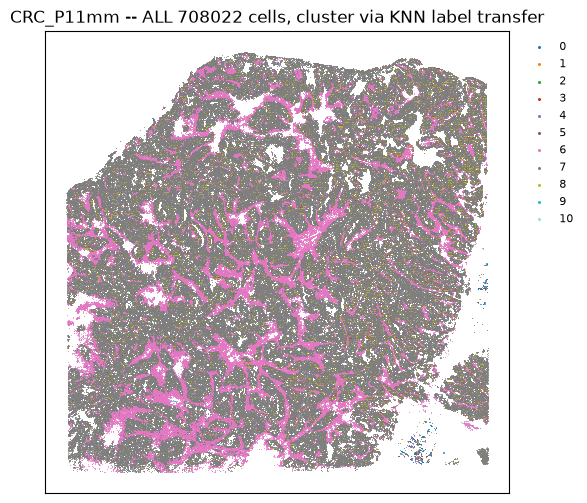

In [30]:
PLOT_SLIDE_FULL = "CRC_P11mm"  # change to inspect a different slide

with h5py.File(TOKEN_RUN_PATH, "r") as f:
    target_code = int(np.nonzero(slide_cats == PLOT_SLIDE_FULL)[0][0])
    full_idx = np.nonzero(slide_codes == target_code)[0]  # np.nonzero already returns ascending order

    trans_full = f["obsm/X_dae_trans_cell"][full_idx]
    token_full = f["obsm/X_dae_token_cell"][full_idx]
    spatial_full = f["obsm/spatial"][full_idx]

X_full = np.concatenate([trans_full, token_full], axis=1).astype(np.float32)
n_in_subsample = int((slide_id == PLOT_SLIDE_FULL).sum())
print(f"{PLOT_SLIDE_FULL}: {len(full_idx)} cells total (vs {n_in_subsample} in the earlier subsample)")

knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(emb_adata.X, emb_adata.obs["leiden"])
pred_leiden = knn.predict(X_full)

full_adata = ad.AnnData(
    X=np.zeros((len(full_idx), 1)),
    obs=pd.DataFrame({"leiden": pd.Categorical(pred_leiden, categories=emb_adata.obs["leiden"].cat.categories)}),
)
full_adata.obsm["spatial"] = spatial_full

pl.plot_spatial_labels(
    full_adata,
    spatial_key="spatial",
    label_key="leiden",
    mode="bin",
    point_size=0.3,  # default is 3 -- this cell has 5-20x more points than the subsample plot above, so smaller still
    title=f"{PLOT_SLIDE_FULL} -- ALL {len(full_idx)} cells, cluster via KNN label transfer",
)
plt.show()

CRC_P1: 59178 cells total (vs 8000 in the earlier subsample)


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


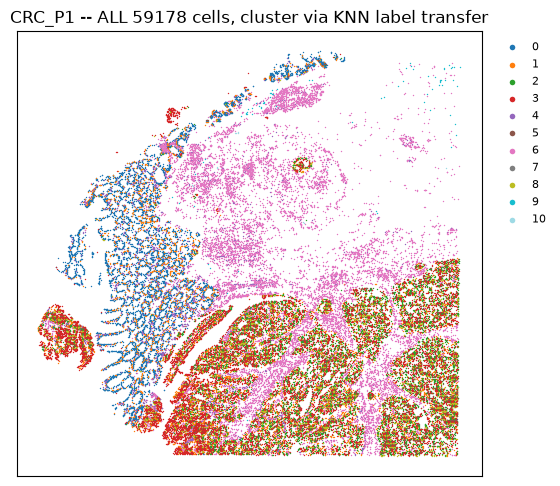

In [31]:
PLOT_SLIDE_FULL = "CRC_P1"  # change to inspect a different slide

with h5py.File(TOKEN_RUN_PATH, "r") as f:
    target_code = int(np.nonzero(slide_cats == PLOT_SLIDE_FULL)[0][0])
    full_idx = np.nonzero(slide_codes == target_code)[0]  # np.nonzero already returns ascending order

    trans_full = f["obsm/X_dae_trans_cell"][full_idx]
    token_full = f["obsm/X_dae_token_cell"][full_idx]
    spatial_full = f["obsm/spatial"][full_idx]

X_full = np.concatenate([trans_full, token_full], axis=1).astype(np.float32)
n_in_subsample = int((slide_id == PLOT_SLIDE_FULL).sum())
print(f"{PLOT_SLIDE_FULL}: {len(full_idx)} cells total (vs {n_in_subsample} in the earlier subsample)")

knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(emb_adata.X, emb_adata.obs["leiden"])
pred_leiden = knn.predict(X_full)

full_adata = ad.AnnData(
    X=np.zeros((len(full_idx), 1)),
    obs=pd.DataFrame({"leiden": pd.Categorical(pred_leiden, categories=emb_adata.obs["leiden"].cat.categories)}),
)
full_adata.obsm["spatial"] = spatial_full

pl.plot_spatial_labels(
    full_adata,
    spatial_key="spatial",
    label_key="leiden",
    mode="bin",
    point_size=1,  # default is 3 -- this cell has 5-20x more points than the subsample plot above, so smaller still
    title=f"{PLOT_SLIDE_FULL} -- ALL {len(full_idx)} cells, cluster via KNN label transfer",
)
plt.show()